# Unidad 3 · Clase 2 — Optimización y **despliegue** de modelos de Deep Learning

**Módulo:** Científico de Datos e IA Aplicada · **Caso:** el clasificador de prendas de la tienda de DevSenior Code (Fashion-MNIST).

> 🎯 **Hoy no entrenamos nada.** El modelo ya está entrenado, podado y cuantizado (viene en `modelos/`).
> Nuestro trabajo es el que hace un ingeniero de IA el lunes por la mañana: **medirlo, empaquetarlo como servicio y dejarlo corriendo**.

```
modelo.h5 ─► medir ─► TFLite ─► API (FastAPI) ─► Docker ─► servidor (SSH) ─► benchmark
```

**Al terminar sabrás:**
1. Medir tamaño, latencia y accuracy de un modelo antes de decidir cómo desplegarlo.
2. Explicar qué hicieron pruning y quantization, y verificar que funcionaron.
3. Servir un modelo con **FastAPI** (carga única, validación, `/health`).
4. Separar configuración y secretos con **`.env`**.
5. Empaquetar el servicio en **Docker** y comparar dos despliegues con **docker compose**.
6. Entender el rol de **SSH** para llegar a un servidor.

> 🧑‍🏫 **Nota para el docente**
>
> **⏱️ Guía de tiempos (≈ 4 h, con pausa)**
> 
> | Tiempo | Sección |
> |---|---|
> | 0:00 – 0:20 | 0. Setup y 1. Del notebook a producción |
> | 0:20 – 0:55 | 2. Medir antes de decidir (tamaño, accuracy, latencia) |
> | 0:55 – 1:15 | 3. Qué hicieron pruning y quantization (sin reentrenar) |
> | 1:15 – 1:25 | ☕ Pausa |
> | 1:25 – 2:15 | 4. API con FastAPI (live coding de `main.py`) |
> | 2:15 – 2:40 | 5. `.env` y secretos |
> | 2:40 – 3:20 | 6. Docker + 7. docker compose (en terminal) |
> | 3:20 – 3:40 | 8. SSH y llegada a un servidor |
> | 3:40 – 4:00 | 9. Checklist, cierre y retos |
> 
> Los bloques de Docker se ejecutan en **terminal** (no en el notebook). Verifica antes de clase que `docker --version` funcione en tu máquina y en las de los estudiantes.

## 0. Preparación

In [1]:
import os
# Los .h5 se guardaron con Keras "legacy" (tf_keras). Debe fijarse ANTES de importar tensorflow.
os.environ.setdefault("TF_USE_LEGACY_KERAS", "1")

import json, shutil, subprocess, sys, tempfile, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import tensorflow as tf

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

# Carpeta raíz de la clase (donde viven modelos/, datos/ y despliegue/)
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "modelos").exists())
MODELOS = ROOT / "modelos"

CLASES = ["Camiseta/top", "Pantalón", "Suéter", "Vestido", "Abrigo",
          "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]

# Muestra de 1 000 imágenes REALES de test (no hace falta internet)
d = np.load(ROOT / "datos" / "fashion_mnist_muestra.npz")
X, y = d["x"], d["y"]                      # X: (1000, 28, 28) uint8 en [0, 255]
Xn = (X / 255.0).astype("float32")[..., None]   # normalizado, con canal: (1000, 28, 28, 1)
print("TensorFlow", tf.__version__, "| muestra:", X.shape, "| carpeta:", ROOT.name)

TensorFlow 2.21.0 | muestra: (1000, 28, 28) | carpeta: out


## 1. Del notebook a producción

Un modelo "que funciona en el notebook" todavía no es un producto. En producción cambian las reglas:

| | Notebook | Producción |
|---|---|---|
| Hardware | GPU, sin prisa | CPU compartida, **milisegundos** |
| Tamaño | irrelevante | arranque, memoria y costo de la imagen |
| Latencia | no se mide | es un **SLA** (p. ej. p95 < 200 ms) |
| Entorno | "en mi máquina funciona" | **idéntico en cualquier lado** (Docker) |
| Secretos | pegados en el código | fuera del código (`.env`) |

Recibimos tres artefactos ya producidos por el equipo de modelado. **Primer reflejo del ingeniero de despliegue: mirar qué recibió.**

> 🧑‍🏫 **Nota para el docente**
>
> **Dilo así:** *"Entrenar es cocinar un plato gourmet con todo el tiempo del mundo. Desplegar es servirlo en un local de comida rápida: sale en segundos y sabe igual en cada pedido."*
> Pregunta de apertura (3 min): *¿qué pasaría si el reconocimiento facial de un celular tardara 3 segundos?*

In [2]:
for f in sorted(MODELOS.iterdir()):
    print(f"{f.name:28} {f.stat().st_size / 1024:>10.1f} KB")

modelo_base.h5                   1284.7 KB
modelo_optimizado.tflite          109.8 KB
modelo_podado.h5                  436.4 KB


**Lectura rápida:** `modelo_base.h5` es el original; `modelo_podado.h5` tiene pesos poda­dos (ya pesa menos al comprimirse); `modelo_optimizado.tflite` es podado **+ cuantizado + formato de inferencia**.

## 2. Medir antes de decidir

La regla de oro: **nunca se optimiza ni se despliega a ciegas**. Medimos tres cosas y las comparamos:

| Métrica | Pregunta |
|---|---|
| **Tamaño** | ¿cuánto pesa el artefacto? |
| **Accuracy** | ¿perdimos calidad al optimizar? |
| **Latencia** | ¿cuántos ms tarda UNA predicción? |

Primero, funciones de evaluación. La de Keras viene lista; **la de TFLite la escribimos nosotros** (es exactamente lo que hará la API).

In [3]:
def evaluar_keras(ruta, n_latencia=200):
    """Accuracy (lote completo) y latencia por imagen (una a una) de un modelo Keras .h5."""
    modelo = tf.keras.models.load_model(ruta)
    pred = modelo.predict(Xn, verbose=0).argmax(axis=1)
    acc = float((pred == y).mean())
    modelo.predict(Xn[:1], verbose=0)                       # calentamiento
    t = time.perf_counter()
    for i in range(n_latencia):
        modelo.predict(Xn[i:i+1], verbose=0)
    lat = (time.perf_counter() - t) / n_latencia * 1000
    return {"accuracy": acc, "latencia_ms": lat}

In [4]:
def evaluar_tflite(ruta, n_latencia=200):
    """Accuracy y latencia por imagen de un modelo .tflite."""
    interprete = tf.lite.Interpreter(model_path=str(ruta))
    interprete.allocate_tensors()
    entrada = interprete.get_input_details()[0]["index"]
    salida = interprete.get_output_details()[0]["index"]

    def predecir(img):                                      # img: (28, 28, 1) float32
        interprete.set_tensor(entrada, img[None, ...])
        interprete.invoke()
        return interprete.get_tensor(salida)[0].argmax()

    pred = np.array([predecir(img) for img in Xn])
    acc = float((pred == y).mean())
    t = time.perf_counter()
    for i in range(n_latencia):
        predecir(Xn[i])
    lat = (time.perf_counter() - t) / n_latencia * 1000
    return {"accuracy": acc, "latencia_ms": lat}

> 🧑‍🏫 **Nota para el docente**
>
> Esta es la celda clave de la sesión: la misma lógica de `set_tensor → invoke → get_tensor` es la que luego va dentro de `model_utils.py`. Insiste en que el intérprete se crea **una vez** y se reutiliza.

In [5]:
tabla = []
for nombre in ["modelo_base.h5", "modelo_podado.h5", "modelo_optimizado.tflite"]:
    ruta = MODELOS / nombre
    r = evaluar_tflite(ruta) if nombre.endswith(".tflite") else evaluar_keras(ruta)
    tabla.append({"modelo": nombre, "tamaño_KB": ruta.stat().st_size / 1024, **r})

df = pd.DataFrame(tabla).set_index("modelo")
df["x_mas_chico"] = df.loc["modelo_base.h5", "tamaño_KB"] / df["tamaño_KB"]
df["x_mas_rapido"] = df.loc["modelo_base.h5", "latencia_ms"] / df["latencia_ms"]
df.round(3)

,tamaño_KB,accuracy,latencia_ms,x_mas_chico,x_mas_rapido
modelo,,,,,
modelo_base.h5,1284.656,0.901,36.374,1.000,1.000
modelo_podado.h5,436.352,0.904,35.161,2.944,1.035
modelo_optimizado.tflite,109.781,0.904,0.020,11.702,1826.603


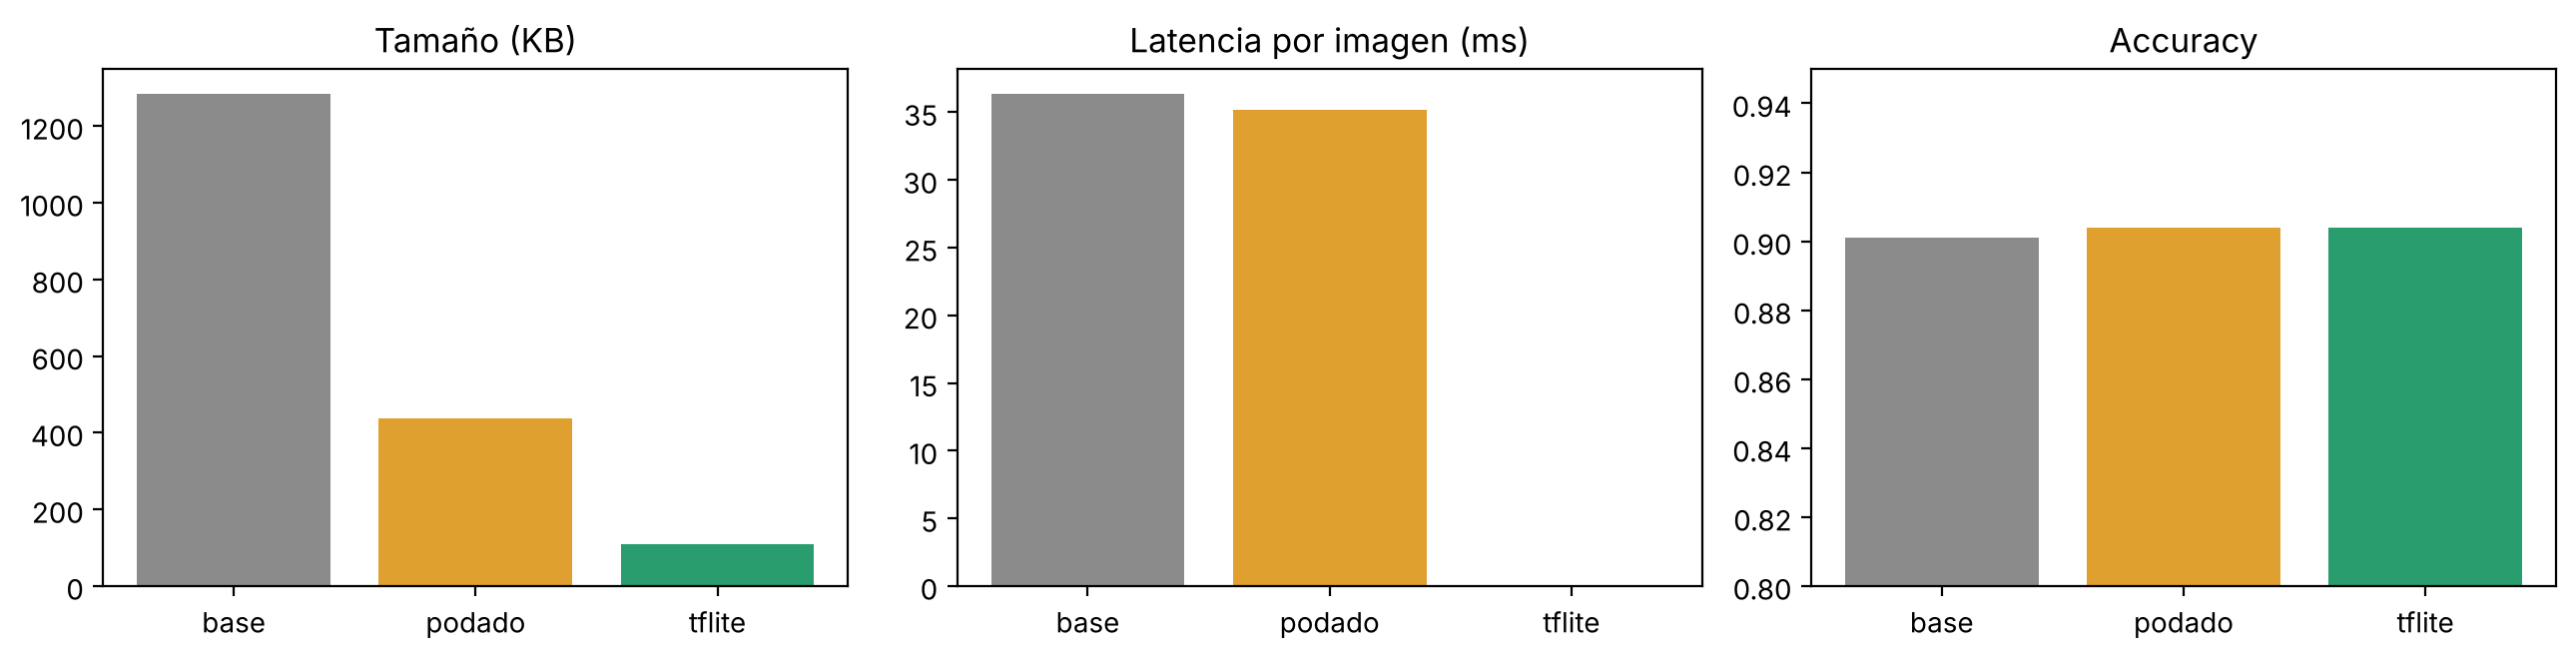

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
colores = ["#8b8b8b", "#e0a030", "#2a9d6f"]
for a, col, titulo in zip(ax, ["tamaño_KB", "latencia_ms", "accuracy"],
                          ["Tamaño (KB)", "Latencia por imagen (ms)", "Accuracy"]):
    a.bar(["base", "podado", "tflite"], df[col], color=colores)
    a.set_title(titulo)
ax[2].set_ylim(0.8, 0.95)
plt.tight_layout(); plt.show()

### 🧠 Interpretar (no solo calcular)
- ¿Perdimos accuracy? Con 1 000 imágenes, diferencias de ±0.5 pts **no son significativas**: es ruido de muestreo.
- La latencia baja de forma espectacular (órdenes de magnitud), pero ojo: comparamos `model.predict()` (pensado para lotes y con mucho *overhead*) contra el intérprete TFLite (pensado para una predicción). Parte de la ganancia es **la herramienta correcta para servir**, no solo la cuantización.
- La decisión: **desplegamos el `.tflite`**.

> 🧑‍🏫 **Nota para el docente**
>
> Pregunta: *¿Y si el accuracy hubiera caído 5 puntos?* → Se vuelve una decisión de negocio (trade-off), no técnica. Mencionar quantization-aware training como salida.

## 3. ¿Qué hicieron *pruning* y *quantization*? (sin reentrenar)

El equipo de modelado aplicó dos técnicas. No las repetimos, pero un buen ingeniero **verifica que hicieron lo que dicen**.

| Técnica | Idea | Qué esperamos ver |
|---|---|---|
| **Pruning** | poner en cero los pesos que casi no aportan | muchos pesos exactamente en 0 |
| **Quantization** | guardar pesos en int8 en vez de float32 | ~4× menos tamaño |
| *Distillation* | un modelo pequeño imita a uno grande | (solo concepto; requiere reentrenar) |

In [7]:
def dispersion(ruta):
    m = tf.keras.models.load_model(ruta)
    pesos = np.concatenate([w.flatten() for w in m.get_weights()])
    return float((pesos == 0).mean()), int(pesos.size)

for nombre in ["modelo_base.h5", "modelo_podado.h5"]:
    frac, total = dispersion(MODELOS / nombre)
    print(f"{nombre:22} {total:>8,} pesos | {frac:6.1%} son exactamente cero")

modelo_base.h5          105,866 pesos |   0.0% son exactamente cero
modelo_podado.h5        105,866 pesos |  49.8% son exactamente cero


**Conversión a TFLite** — esto sí es parte del despliegue (es rápido y no reentrena). Probemos dos tipos de cuantización sobre el modelo podado y comparemos tamaños:

In [8]:
def convertir(ruta_h5, modo):
    modelo = tf.keras.models.load_model(ruta_h5)
    conv = tf.lite.TFLiteConverter.from_keras_model(modelo)
    if modo == "dinamica":                         # pesos int8, activaciones float
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
    elif modo == "float16":                        # pesos float16
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.target_spec.supported_types = [tf.float16]
    return conv.convert()                          # bytes del .tflite

for modo in ["sin cuantizar", "dinamica", "float16"]:
    blob = convertir(MODELOS / "modelo_podado.h5", modo)
    print(f"{modo:15} {len(blob) / 1024:8.1f} KB")

sin cuantizar      417.2 KB


dinamica           110.9 KB


float16            211.8 KB


| Tipo | Pesos | Tamaño típico | Cuándo |
|---|---|---|---|
| Dinámica (int8) | int8 | ~4× menos | punto de partida, sin datos de calibración |
| Float16 | float16 | ~2× menos | si el hardware lo soporta (GPU/edge) |
| Entera completa (int8) | int8 + activaciones | ~4× y más rápido en CPU/edge | móviles, microcontroladores; **requiere dataset de calibración** |
| QAT | int8 simulado al entrenar | ~4× con menos pérdida | cuando la post-training degrada demasiado |

**Formatos de despliegue:** `SavedModel` (TF Serving) · `.h5` (legado, no para producción nueva) · **`.tflite`** (liviano, móviles/microservicios) · **`.onnx`** (portable entre frameworks, ONNX Runtime/TensorRT).

> 🧑‍🏫 **Nota para el docente**
>
> Aviso de versión: `tf.lite.Interpreter` está marcado como *deprecated* en TF recientes; el reemplazo es `ai_edge_litert` (LiteRT), mismo API. En la imagen Docker fijamos TF 2.16.1 donde funciona sin avisos. Buen momento para hablar de **fijar versiones** en producción.

## 4. Servir el modelo: una API con FastAPI

Un modelo solo sirve si otros sistemas pueden **pedirle** predicciones. Lo exponemos por HTTP:

```
cliente ──POST /predict {imagen}──► [ FastAPI ► valida ► TFLite ] ──► {clase, confianza, latencia}
          ◄──────── JSON ─────────
```

Buenas prácticas que aplicamos:
1. **Cargar el modelo una sola vez** al arrancar (jamás en cada petición).
2. **Validar** la entrada con Pydantic (errores claros, no silenciosos).
3. Separar `model_utils.py` (inferencia) de `main.py` (endpoints).
4. Exponer **`/health`** para que Docker/Kubernetes sepan si el servicio vive.

Armamos una API de trabajo en `api_trabajo/`. Los esquemas y las utilidades vienen listos; **el `main.py` lo escribimos juntos.**

In [9]:
API_DIR = ROOT / "api_trabajo"
(API_DIR / "app").mkdir(parents=True, exist_ok=True)
(API_DIR / "model").mkdir(exist_ok=True)
shutil.copy(MODELOS / "modelo_optimizado.tflite", API_DIR / "model" / "modelo_optimizado.tflite")

# Reutilizamos los módulos ya probados del proyecto de despliegue
BASE_PROY = ROOT / "despliegue" / "01_api_fastapi_docker" / "app"
for nombre in ["__init__.py", "schemas.py", "model_utils.py"]:
    shutil.copy(BASE_PROY / nombre, API_DIR / "app" / nombre)

print((API_DIR / "app" / "schemas.py").read_text()[:900])

"""Esquemas de entrada/salida de la API, validados con Pydantic."""
from typing import List

from pydantic import BaseModel, Field


class PredictionRequest(BaseModel):
    """Imagen en escala de grises de 28x28 (valores en [0, 255] o en [0, 1])."""
    imagen: List[List[float]] = Field(
        ...,
        description="Matriz 28x28 de intensidades de píxel",
        min_length=28,
        max_length=28,
    )


class PredictionResponse(BaseModel):
    clase_id: int
    clase_nombre: str
    confianza: float
    latencia_ms: float


class HealthResponse(BaseModel):
    status: str
    modelo_cargado: bool
    version_modelo: str



In [10]:
codigo_main = """
import logging
import os
from contextlib import asynccontextmanager

import numpy as np
from fastapi import Depends, FastAPI, Header, HTTPException

from app.model_utils import obtener_modelo
from app.schemas import HealthResponse, PredictionRequest, PredictionResponse

logging.basicConfig(level=os.environ.get("LOG_LEVEL", "INFO").upper())
logger = logging.getLogger("inference-api")
_modelo = None


@asynccontextmanager
async def lifespan(app: FastAPI):
    global _modelo
    try:
        _modelo = obtener_modelo()          # se carga UNA vez, al arrancar
        logger.info("Modelo cargado")
    except FileNotFoundError as exc:
        logger.warning("Modelo no disponible: %s", exc)
    yield


app = FastAPI(title="Inferencia Fashion-MNIST", version="1.0.0", lifespan=lifespan)


def verificar_api_key(x_api_key: str | None = Header(default=None)):
    esperada = os.environ.get("API_KEY")
    if esperada and x_api_key != esperada:
        raise HTTPException(status_code=401, detail="API key inválida o ausente")


@app.get("/health", response_model=HealthResponse)
def health():
    return HealthResponse(status="ok", modelo_cargado=_modelo is not None,
                          version_modelo="modelo_optimizado.tflite" if _modelo else "no_cargado")


@app.post("/predict", response_model=PredictionResponse, dependencies=[Depends(verificar_api_key)])
def predict(request: PredictionRequest):
    if _modelo is None:
        raise HTTPException(status_code=503, detail="El modelo no está cargado")
    try:
        return PredictionResponse(**_modelo.predecir(np.array(request.imagen)))
    except ValueError as exc:
        raise HTTPException(status_code=422, detail=str(exc))
"""
(API_DIR / "app" / "main.py").write_text(codigo_main.strip() + "\n", encoding="utf-8")
print("main.py escrito:", (API_DIR / "app" / "main.py").stat().st_size, "bytes")

main.py escrito: 1697 bytes


> 🧑‍🏫 **Nota para el docente**
>
> Live coding en 3 pasos: (1) `/health` solo, probarlo; (2) `/predict` sin validación; (3) agregar 503/422. Si el tiempo aprieta, entregar el `main.py` ya escrito y comentarlo línea a línea. La parte de `verificar_api_key` se explica en la sección 5.

Levantamos el servidor **desde el notebook** (proceso aparte) y le hablamos como lo haría cualquier cliente:

In [11]:
def levantar_api(puerto=8010, extra_env=None):
    env = {**os.environ, **(extra_env or {})}
    proc = subprocess.Popen(
        [sys.executable, "-m", "uvicorn", "app.main:app", "--port", str(puerto)],
        cwd=API_DIR, env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(60):                               # espera a que /health responda
        try:
            if requests.get(f"http://127.0.0.1:{puerto}/health", timeout=1).ok:
                return proc
        except requests.exceptions.RequestException:
            time.sleep(1)
    proc.kill(); raise RuntimeError("La API no arrancó")

api = levantar_api()
URL = "http://127.0.0.1:8010"
print(requests.get(f"{URL}/health").json())

{'status': 'ok', 'modelo_cargado': True, 'version_modelo': 'modelo_optimizado.tflite'}


In [12]:
resp = requests.post(f"{URL}/predict", json={"imagen": X[0].tolist()})
print(resp.status_code, resp.json())
print("Etiqueta real:", CLASES[y[0]])

200 {'clase_id': 5, 'clase_nombre': 'Sandalia', 'confianza': 0.9999980926513672, 'latencia_ms': 0.307}
Etiqueta real: Sandalia


In [13]:
# Casos de error: una API robusta responde con códigos HTTP claros
malo = requests.post(f"{URL}/predict", json={"imagen": [[0.0] * 5] * 28})   # 28 filas pero 5 columnas
print("Imagen mal formada ->", malo.status_code, malo.json()["detail"][:2] if malo.status_code == 422 else malo.json())

vacio = requests.post(f"{URL}/predict", json={})
print("Sin campo 'imagen' ->", vacio.status_code)

Imagen mal formada -> 422 Se
Sin campo 'imagen' -> 422


In [14]:
n = 200
total, interna = [], []
for i in range(n):
    t = time.perf_counter()
    r = requests.post(f"{URL}/predict", json={"imagen": X[i].tolist()}).json()
    total.append((time.perf_counter() - t) * 1000)
    interna.append(r["latencia_ms"])

print(f"Latencia interna del modelo : {np.mean(interna):7.3f} ms")
print(f"Latencia extremo a extremo  : {np.mean(total):7.3f} ms  (p95 = {np.percentile(total, 95):.2f} ms)")

Latencia interna del modelo :   0.061 ms
Latencia extremo a extremo  :   2.440 ms  (p95 = 3.22 ms)


**Idea central:** la latencia que ve el usuario = *inferencia* + *serialización JSON* + *red* + *framework*. Optimizar el modelo ataca solo la primera parte; en producción hay que medir la **latencia extremo a extremo**.

Abre ahora `http://127.0.0.1:8010/docs`: FastAPI generó una documentación interactiva sin escribir una línea extra.

In [15]:
api.terminate(); api.wait()
print("API detenida")

API detenida


## 5. Configuración y secretos: archivos `.env`

Un `.env` guarda la configuración **que cambia entre entornos o que es secreta** (rutas, niveles de log, API keys). El código no debe tener esos valores pegados.

| Sin `.env` | Con `.env` |
|---|---|
| Claves en el código → quedan en el historial de git | Los secretos viven fuera del repositorio |
| Un `main.py` distinto por entorno | El mismo código sirve en dev, staging y producción |
| Cambiar un valor = redesplegar código | Cambiar el `.env` y reiniciar |

**Regla de oro:** el `.env` real **nunca** se versiona (va en `.gitignore` y `.dockerignore`); se versiona un `.env.example` sin valores sensibles.

Nuestra API ya lee `LOG_LEVEL` y `API_KEY` del entorno. Si `API_KEY` existe, `/predict` exige la cabecera `X-API-Key`.

In [16]:
(API_DIR / ".env").write_text("LOG_LEVEL=DEBUG\nAPI_KEY=clave-de-clase-2\n", encoding="utf-8")

def leer_env(ruta):
    pares = {}
    for linea in Path(ruta).read_text().splitlines():
        if linea.strip() and not linea.startswith("#"):
            k, v = linea.split("=", 1)
            pares[k.strip()] = v.strip()
    return pares

config = leer_env(API_DIR / ".env")
print({k: ("***" if "KEY" in k else v) for k, v in config.items()})   # ¡nunca imprimas secretos!

{'LOG_LEVEL': 'DEBUG', 'API_KEY': '***'}


In [17]:
api = levantar_api(8011, extra_env=config)       # el entorno del proceso viene del .env
URL = "http://127.0.0.1:8011"

sin_clave = requests.post(f"{URL}/predict", json={"imagen": X[0].tolist()})
con_clave = requests.post(f"{URL}/predict", json={"imagen": X[0].tolist()},
                          headers={"X-API-Key": config["API_KEY"]})
print("Sin clave:", sin_clave.status_code, sin_clave.json())
print("Con clave:", con_clave.status_code, con_clave.json()["clase_nombre"])

api.terminate(); _ = api.wait()

Sin clave: 401 {'detail': 'API key inválida o ausente'}
Con clave: 200 Sandalia


> 🧑‍🏫 **Nota para el docente**
>
> Pregunta de cierre: *¿por qué sería un error `COPY .env .` dentro del Dockerfile?* → la imagen queda atada a un entorno y los secretos quedan embebidos en las capas (visibles aunque luego borres el archivo). Se pasa en ejecución: `docker run --env-file .env ...`.

## 6. Empaquetar con Docker

> *"Funciona en mi máquina"* deja de ser excusa: la **imagen** lleva el sistema, las dependencias, el código y el modelo.

| Concepto | Qué es | Analogía |
|---|---|---|
| **Dockerfile** | receta de construcción | la receta impresa |
| **Imagen** | plantilla inmutable | el plato "empaquetado" |
| **Contenedor** | imagen en ejecución | el plato servido |
| **Registry** | donde se guardan imágenes | el recetario compartido |

Este es el Dockerfile del proyecto (léelo, cada línea tiene una razón):

In [18]:
print((ROOT / "despliegue" / "01_api_fastapi_docker" / "Dockerfile").read_text())

FROM python:3.11-slim

WORKDIR /app

# requirements primero: si solo cambia el código, esta capa queda en caché
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# Código y modelo ya optimizado (NO el entrenamiento, NO el .env)
COPY app/ ./app
COPY model/ ./model

EXPOSE 8000

HEALTHCHECK --interval=15s --timeout=3s --start-period=20s \
    CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')" || exit 1

CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]



**Por qué está escrito así**
- `python:3.11-slim`: base pequeña → menos superficie de ataque y builds más rápidos.
- `COPY requirements.txt` **antes** que el código: si solo cambias código, Docker reutiliza la capa de `pip install` (caché de capas).
- Solo se copian `app/` y `model/`: **ni entrenamiento, ni datos, ni `.env`** (por eso el `.dockerignore`).
- `HEALTHCHECK` usa nuestro `/health`: Docker marca el contenedor como *healthy* solo cuando el modelo cargó.
- Versiones fijas en `requirements.txt`: la imagen de hoy = la de dentro de seis meses.

### 💻 Ahora en la **terminal** (no en el notebook)
```bash
cd despliegue/01_api_fastapi_docker

# 1. Construir la imagen
docker build -t clase02-inference-api .

# 2. Ejecutar el contenedor pasando la configuración por entorno (sin copiar el .env a la imagen)
cp .env.example .env            # edita API_KEY
docker run -d --name api --env-file .env -p 8000:8000 clase02-inference-api

# 3. Verificar
docker ps                        # estado "healthy" tras unos segundos
python test_api.py --api-key LA_CLAVE_QUE_PUSISTE
docker logs api                  # los logs de la aplicación

# 4. Limpiar
docker stop api && docker rm api
```

In [19]:
# ¿Tienes Docker disponible en esta máquina?
if shutil.which("docker"):
    print(subprocess.run(["docker", "--version"], capture_output=True, text=True).stdout.strip())
else:
    print("Docker no está instalado/en el PATH. Instálalo (Docker Desktop) o sigue la demo del docente.")

Docker version 29.9.2, build a82e528


### 🧩 Reflexión: ¿cuánto pesa la imagen?
Corre `docker images clase02-inference-api`. Verás **más de 1 GB**: el modelo pesa 110 KB, ¡pero `tensorflow-cpu` pesa cientos de MB! Para servir un `.tflite` solo necesitamos el *runtime*, no todo TensorFlow.
**Reto:** reemplazar `tensorflow-cpu` por `ai-edge-litert` (mismo `Interpreter`) y comparar el tamaño final de la imagen. Esa es la verdadera optimización de despliegue.

> 🧑‍🏫 **Nota para el docente**
>
> Si Docker no corre en alguna máquina de clase, usa la tuya como demo y que el resto observe. Plan B: Play with Docker / GitHub Codespaces. El primer build tarda varios minutos (descarga TensorFlow): lánzalo al empezar la sección 4 en segundo plano.

## 7. Dos despliegues, un comando: `docker compose`

Para comparar **base vs optimizado** en condiciones reales levantamos los dos servicios a la vez:

| Servicio | Modelo | Puerto |
|---|---|---|
| `modelo-base` | `modelo_base.h5` con Keras | 8001 |
| `modelo-optimizado` | `modelo_optimizado.tflite` | 8002 |

```bash
cd despliegue/02_benchmark_compose
docker compose up --build -d            # construye y levanta ambos
docker compose ps                        # ambos "healthy"

pip install -r benchmark/requirements.txt
python benchmark/compare.py --n 200      # mismas imágenes reales a los dos; genera benchmark/reporte.md

docker compose down                      # apagar y limpiar
```

El script mide **tamaño, latencia (media y p95), throughput y accuracy** con las mismas 200 imágenes.

In [20]:
reporte = ROOT / "despliegue" / "02_benchmark_compose" / "benchmark" / "reporte.md"
print(reporte.read_text() if reporte.exists() else "Aún no hay reporte: corre benchmark/compare.py en la terminal y vuelve a ejecutar esta celda.")

Aún no hay reporte: corre benchmark/compare.py en la terminal y vuelve a ejecutar esta celda.


### Cómo leer el resultado
- **p95** importa más que el promedio: es lo que vive el 5 % de usuarios más desafortunado (los SLA se definen sobre percentiles).
- **Throughput** = peticiones/segundo que aguanta *este* contenedor. Si necesitas más, se escala **horizontalmente** (más réplicas detrás de un balanceador).
- Si el accuracy es igual y la latencia baja, la optimización fue gratis; si no, es un trade-off que se discute con negocio.

## 8. ¿Cómo llega todo esto a un servidor? SSH

Construimos la imagen en nuestra máquina. Para ejecutarla en un servidor (EC2, VM de GCP/Azure, un VPS, un servidor de la empresa) nos conectamos por **SSH**: un canal cifrado donde **la llave privada nunca viaja**.

```
Tu máquina                         Servidor
[ llave PRIVADA ] ◄─ desafío ─►  [ llave PÚBLICA en ~/.ssh/authorized_keys ]
```
*La pública es un candado que le entregas al servidor; la privada es la única llave que lo abre.*

```bash
ssh-keygen -t ed25519 -C "tu_correo@ejemplo.com"     # una sola vez
ssh-copy-id usuario@servidor                         # instala tu llave pública
ssh usuario@servidor                                 # entrar sin contraseña
scp modelo_optimizado.tflite usuario@servidor:/srv/modelos/
ssh usuario@servidor "docker compose up -d"          # desplegar sin sesión interactiva
```

In [21]:
carpeta = Path(tempfile.mkdtemp(prefix="ssh_demo_"))
llave = carpeta / "id_demo"
if shutil.which("ssh-keygen"):
    subprocess.run(["ssh-keygen", "-t", "ed25519", "-N", "", "-C", "demo-clase2", "-f", str(llave), "-q"], check=True)
    print("PÚBLICA (se comparte):\n ", llave.with_suffix(".pub").read_text().strip())
    print("\nPRIVADA (NUNCA se comparte): empieza con ->", llave.read_text().splitlines()[0])
else:
    print("ssh-keygen no está disponible en esta máquina.")
shutil.rmtree(carpeta, ignore_errors=True)          # es una llave de demostración: la borramos

ssh-keygen no está disponible en esta máquina.


**Buenas prácticas:** autenticar siempre con **llaves** (nunca contraseña) · proteger la privada con *passphrase* · no subirla jamás a git (GitHub escanea y alerta de fugas) · usar `~/.ssh/config`:
```
Host servidor-produccion
    HostName 203.0.113.10
    User despliegue
    IdentityFile ~/.ssh/id_ed25519
```

> 🧑‍🏫 **Nota para el docente**
>
> Demo opcional de 3 min: buscar "GitHub secret scanning" y mostrar qué pasa si una llave privada o `.env` llega a un repo público. Conecta con la regla de oro del `.env`.

## 9. Checklist de despliegue

- [ ] **Medí** tamaño, accuracy y latencia (y la latencia *extremo a extremo*)
- [ ] El modelo se **carga una sola vez**, al arrancar
- [ ] Entrada **validada** (Pydantic) y errores con códigos HTTP claros
- [ ] Endpoint **`/health`** y `HEALTHCHECK` en el Dockerfile
- [ ] Configuración y secretos en **`.env`** (fuera de git y fuera de la imagen)
- [ ] Imagen **slim**, dependencias **fijadas**, solo lo necesario dentro
- [ ] Probé con **datos reales**, no con ruido aleatorio
- [ ] Sé cómo **llegar al servidor** (SSH con llaves) y cómo hacer *rollback* (imagen anterior)

## 🏁 Retos (tarea)
1. Cambia a **float16** en la conversión y compara tamaño/latencia con el dinámico.
2. Añade un endpoint **`/predict_batch`** que acepte varias imágenes.
3. Reemplaza `tensorflow-cpu` por **`ai-edge-litert`** en la imagen y compara el tamaño final.
4. Haz un **multi-stage build** del Dockerfile.
5. Agrega un tercer servicio al compose con el modelo **podado sin cuantizar** y compara los tres.
6. Exporta a **ONNX** (`tf2onnx`) y sirve con `onnxruntime`.

## 🔭 Puente a la siguiente clase
Si esta API recibiera 10 000 peticiones por segundo, ¿qué cambiaría? ¿Cómo versionarías el modelo en producción? ¿Y si el **entrenamiento** también viviera en una plataforma como **Databricks**?

In [22]:
# Limpieza: elimina la carpeta de trabajo creada durante la clase
shutil.rmtree(ROOT / "api_trabajo", ignore_errors=True)
print("Listo ✅")

Listo ✅
